# Phase 1 — Model 1 · Decoder Transformer

Train the causal decoder, then generate continuations from the selected checkpoint.

## Required files and runtime

- Extracted `phase1_scratch_data/` from the preparation notebook or its saved backup. Keep `manifest.json`, `tokenizer.json`, the train/validation token streams, and the held-out prompt and truth files.
- Attach the official test prompt JSON or allow the notebook to fetch it using the authorized `HF_TOKEN` Kaggle secret. The held-out scorer is included in the notebook.
- A GPU for training and generation. Attach a saved run folder when resuming.
- For generation from an existing checkpoint, the run folder needs `best.pt`, `tokenizer.json`, and `run_config.json`. The held-out files are needed for dev evaluation.

## 1. Setup and paths

In [8]:
import subprocess
import sys

subprocess.run([
    sys.executable, "-m", "pip", "install", "-q",
    "numpy>=1.26,<3", "huggingface-hub>=0.30,<2",
    "ijson>=3.3,<4", "matplotlib>=3.8,<4"
], check=True)


CompletedProcess(args=['/usr/bin/python3', '-m', 'pip', 'install', '-q', 'numpy>=1.26,<3', 'huggingface-hub>=0.30,<2', 'ijson>=3.3,<4', 'matplotlib>=3.8,<4'], returncode=0)

In [ ]:
import copy
import gc
import hashlib
import heapq
import json
import math
import os
import random
import re
import shutil
import sqlite3
import time
import zipfile
from collections import Counter, defaultdict
from pathlib import Path
from types import SimpleNamespace

import numpy as np
import torch
from torch import nn
from torch.nn import functional as F
from torch.utils.checkpoint import checkpoint
import matplotlib.pyplot as plt
from IPython.display import display, Image, FileLink


In [ ]:
DATA_DIR = Path("/kaggle/working/phase1_scratch_data")
RUN_DIR = Path("/kaggle/working/decoder_scratch_bpe_run")
RESUME_FROM = None
LOCAL_TEST_PROMPTS = None
MAX_TRAIN_STEPS = 7600

CONFIG = {
    "seed": 42,
    "repo": "Exploration-Lab/CS-781-Capstone",
    "train_tokens": 810000000,
    "val_tokens": 2000000,
    "tokenizer_chars": 100000000,
    "vocab_size": 32768,
    "validation_fraction": 0.02,
    "mix": {
        "supreme_court": 0.35,
        "high_courts": 0.3,
        "acts": 0.2,
        "tribunals": 0.15
    },
    "model": {
        "width": 704,
        "layers": 16,
        "heads": 11,
        "context": 2048,
        "dropout": 0.0
    },
    "train": {
        "sequence_length": 2048,
        "micro_batch": 1,
        "accumulation": 16,
        "lr": 0.0003,
        "min_lr": 3e-05,
        "warmup_fraction": 0.03,
        "weight_decay": 0.1,
        "clip": 1.0,
        "eval_every": 250,
        "save_every": 100,
        "log_every": 10,
        "max_hours": 10.5
    }
}

In [11]:
try:
    from kaggle_secrets import UserSecretsClient
    secrets = UserSecretsClient()
    for name in ("HF_TOKEN", "HF"):
        try:
            token = secrets.get_secret(name)
            if token:
                os.environ["HF_TOKEN"] = token
                break
        except Exception:
            pass
except ImportError:
    pass

print("HF token available:", bool(os.environ.get("HF_TOKEN")))
print("CUDA available:", torch.cuda.is_available())
print("GPU count:", torch.cuda.device_count())
for i in range(torch.cuda.device_count()):
    gpu = torch.cuda.get_device_properties(i)
    print(i, gpu.name, round(gpu.total_memory / 2**30, 2), "GiB")


HF token available: True
CUDA available: True
GPU count: 2
0 Tesla T4 14.56 GiB
1 Tesla T4 14.56 GiB


## 2. Data and tokenizer

In [ ]:
SOURCES = ("supreme_court", "high_courts", "acts", "tribunals")
SPECIALS = ["<pad>", "<unk>", "<s>", "</s>"]
PAD, UNK, BOS, EOS = range(4)
IMPLEMENTATION_VERSION = "single-notebook-handwritten-bpe-v2"


In [ ]:
def digest_file(path):
    h = hashlib.sha256()
    with open(path, 'rb') as f:
        for chunk in iter(lambda: f.read(8 * 1024 * 1024), b''):
            h.update(chunk)
    return h.hexdigest()


In [ ]:
def fingerprint(text):
    return hashlib.sha256(text.encode('utf-8')).hexdigest()


In [ ]:
def write_json(path, value):
    path = Path(path)
    path.parent.mkdir(parents=True, exist_ok=True)
    tmp = path.with_suffix(path.suffix + '.tmp')
    tmp.write_text(json.dumps(value, indent=2, ensure_ascii=False), encoding='utf-8')
    os.replace(tmp, path)


In [ ]:
def read_config(path):
    return json.loads(Path(path).read_text(encoding='utf-8'))


In [ ]:
def split_bpe_pieces(text, max_chars=256):
    """Keep every character; separate words, punctuation and whitespace.

    An optional leading ASCII space can join a word or punctuation piece.
    Long pieces are split into bounded chunks to limit per-piece work.
    No normalization, strip(), split(), external tokenizer or regex package.
    """
    for match in re.finditer(' ?\\w+| ?[^\\w\\s]+|\\s+', text):
        piece = match.group(0)
        for start in range(0, len(piece), max_chars):
            yield piece[start:start + max_chars].encode('utf-8')


In [ ]:
def apply_bpe_merges(piece, merge_ranks):
    """Apply learned merges by rank, breaking occurrence ties left-to-right.

    Token IDs 0..3 are reserved. Byte b always has ID b+4. A linked list
    and a heap avoid repeatedly scanning every adjacent pair in a piece.
    """
    ids = [byte + 4 for byte in piece]
    size = len(ids)
    if size < 2 or not merge_ranks:
        return tuple(ids)
    previous = [i - 1 for i in range(size)]
    following = [i + 1 for i in range(size)]
    following[-1] = -1
    active = [True] * size
    queue = []

    def offer(left):
        if left < 0 or not active[left]:
            return
        right = following[left]
        if right < 0:
            return
        pair = (ids[left], ids[right])
        rank = merge_ranks.get(pair)
        if rank is not None:
            heapq.heappush(queue, (rank, left, right, pair[0], pair[1]))
    for left in range(size - 1):
        offer(left)
    while queue:
        rank, left, right, a, b = heapq.heappop(queue)
        if not active[left] or not active[right] or following[left] != right:
            continue
        if ids[left] != a or ids[right] != b:
            continue
        ids[left] = 260 + rank
        active[right] = False
        following[left] = following[right]
        if following[right] >= 0:
            previous[following[right]] = left
        offer(previous[left])
        offer(left)
    result = []
    position = 0
    while position >= 0:
        result.append(ids[position])
        position = following[position]
    return tuple(result)


In [ ]:
class ScratchByteBPE:
    """Our byte BPE vocabulary, encoder, decoder and JSON serialization.

    All base bytes and EVERY intermediate merge token are retained.
    Integer IDs identify symbols; concatenated decimal strings are never used.
    Literal '<s>' etc. in ordinary input are encoded as text, not control IDs.
    """
    FORMAT = 'handwritten-byte-bpe-v1'
    PATTERN = ' ?\\w+| ?[^\\w\\s]+|\\s+'

    def __init__(self, merges=None, max_piece_chars=256):
        self.specials = ['<pad>', '<unk>', '<s>', '</s>']
        self.max_piece_chars = max_piece_chars
        if not isinstance(max_piece_chars, int) or max_piece_chars < 1:
            raise ValueError('max_piece_chars must be a positive integer')
        self.merges = []
        self.merge_ranks = {}
        self.token_bytes = [None] * 4 + [bytes([b]) for b in range(256)]
        self._cache = {}
        for pair in merges or []:
            self.add_merge(tuple(pair))

    def add_merge(self, pair):
        if len(pair) != 2 or pair in self.merge_ranks:
            raise ValueError('Invalid or repeated merge pair')
        if any((type(token) is not int or not 4 <= token < len(self.token_bytes) for token in pair)):
            raise ValueError('A merge must reference earlier non-special token IDs')
        new_id = len(self.token_bytes)
        self.merge_ranks[pair] = len(self.merges)
        self.merges.append(pair)
        self.token_bytes.append(self.token_bytes[pair[0]] + self.token_bytes[pair[1]])
        self._cache.clear()
        return new_id

    def get_vocab_size(self):
        return len(self.token_bytes)

    def token_to_id(self, special):
        return self.specials.index(special) if special in self.specials else None

    def encode(self, text):
        if not isinstance(text, str):
            raise TypeError('encode expects a string')
        output = []
        for piece in split_bpe_pieces(text, self.max_piece_chars):
            encoded = self._cache.get(piece)
            if encoded is None:
                encoded = apply_bpe_merges(piece, self.merge_ranks)
                if len(self._cache) >= 65536:
                    self._cache.clear()
                self._cache[piece] = encoded
            output.extend(encoded)
        return SimpleNamespace(ids=output)

    def decode(self, ids, skip_special_tokens=True):
        chunks = []
        for value in ids:
            token = int(value)
            if not 0 <= token < len(self.token_bytes):
                raise ValueError(f'Unknown token ID: {token}')
            if token < 4:
                if not skip_special_tokens:
                    chunks.append(self.specials[token].encode('utf-8'))
            else:
                chunks.append(self.token_bytes[token])
        return b''.join(chunks).decode('utf-8', errors='replace')

    def save(self, path, training=None):
        payload = {'format': self.FORMAT, 'special_tokens': self.specials, 'byte_offset': 4, 'pattern': self.PATTERN, 'max_piece_chars': self.max_piece_chars, 'merges': self.merges, 'vocab_hex': [None if value is None else value.hex() for value in self.token_bytes]}
        if training is not None:
            payload['training'] = training
        path = Path(path)
        path.parent.mkdir(parents=True, exist_ok=True)
        temporary = path.with_suffix(path.suffix + '.tmp')
        temporary.write_text(json.dumps(payload, ensure_ascii=False), encoding='utf-8')
        temporary.replace(path)

    @classmethod
    def from_file(cls, path):
        payload = json.loads(Path(path).read_text(encoding='utf-8'))
        if payload.get('format') != cls.FORMAT:
            raise ValueError('This is not our handwritten BPE format. Use a fresh data directory and retrain the tokenizer/token arrays.')
        if payload.get('special_tokens') != ['<pad>', '<unk>', '<s>', '</s>']:
            raise ValueError('Special-token IDs do not match')
        if payload.get('byte_offset') != 4 or payload.get('pattern') != cls.PATTERN:
            raise ValueError('Byte mapping or splitting rules do not match')
        tokenizer = cls(payload['merges'], payload['max_piece_chars'])
        expected = [None if value is None else value.hex() for value in tokenizer.token_bytes]
        if payload.get('vocab_hex') != expected:
            raise ValueError('Vocabulary is inconsistent with the merge history')
        return tokenizer


In [ ]:
class Blocks:
    """Every stored target is used once; final partial blocks use ignored labels.

    Each source stores [BOS, target_1, ..., target_N]. Adjacent blocks overlap
    by one input token, so no target is dropped or duplicated.
    """

    def __init__(self, root, split, length, seed):
        self.length = length
        self.arrays = [np.memmap(Path(root) / f'{s}.{split}.bin', mode='r', dtype='<u2') for s in SOURCES]
        self.descriptors = []
        for source, array in enumerate(self.arrays):
            for start in range(0, len(array) - 1, length):
                self.descriptors.append((source, start, min(length, len(array) - 1 - start)))
        self.order = np.arange(len(self.descriptors))
        if split == 'train':
            np.random.default_rng(seed).shuffle(self.order)
        self.targets = sum((len(a) - 1 for a in self.arrays))

    def __len__(self):
        return len(self.order)

    def close(self):
        for array in self.arrays:
            array._mmap.close()

    def valid_in_range(self, start, stop):
        return sum((self.descriptors[self.order[i]][2] for i in range(start, min(stop, len(self)))))

    def batch(self, indices, device):
        x = np.full((len(indices), self.length), PAD, dtype=np.int64)
        y = np.full_like(x, -100)
        for row, i in enumerate(indices):
            if i >= len(self):
                continue
            source, start, n = self.descriptors[self.order[i]]
            a = self.arrays[source]
            x[row, :n], y[row, :n] = (a[start:start + n], a[start + 1:start + n + 1])
        return (torch.from_numpy(x).to(device), torch.from_numpy(y).to(device))


## 3. Decoder architecture

In [ ]:
class Attention(nn.Module):

    def __init__(self, width, heads, dropout):
        super().__init__()
        assert width % heads == 0
        self.heads, self.dim, self.dropout = (heads, width // heads, dropout)
        self.qkv = nn.Linear(width, 3 * width)
        self.proj = nn.Linear(width, width)

    def forward(self, x, past=None, cache=False):
        b, t, c = x.shape
        q, k, v = self.qkv(x).view(b, t, 3, self.heads, self.dim).unbind(2)
        q, k, v = (a.transpose(1, 2) for a in (q, k, v))
        if past is not None:
            if t != 1:
                raise ValueError('Cached decoding accepts one new token at a time')
            k, v = (torch.cat((past[0], k), 2), torch.cat((past[1], v), 2))
        y = F.scaled_dot_product_attention(q, k, v, dropout_p=self.dropout if self.training else 0.0, is_causal=past is None)
        return (self.proj(y.transpose(1, 2).contiguous().view(b, t, c)), (k, v) if cache else None)


In [ ]:
class Block(nn.Module):

    def __init__(self, width, heads, dropout):
        super().__init__()
        self.ln1, self.ln2 = (nn.LayerNorm(width), nn.LayerNorm(width))
        self.attn = Attention(width, heads, dropout)
        self.mlp = nn.Sequential(nn.Linear(width, 4 * width), nn.GELU(), nn.Linear(4 * width, width))
        self.drop = nn.Dropout(dropout)

    def forward(self, x, past=None, cache=False):
        a, kv = self.attn(self.ln1(x), past, cache)
        x = x + self.drop(a)
        return (x + self.drop(self.mlp(self.ln2(x))), kv)


In [ ]:
class DecoderLM(nn.Module):

    def __init__(self, vocab_size=32768, width=704, layers=16, heads=11, context=2048, dropout=0.0):
        super().__init__()
        self.config = dict(vocab_size=vocab_size, width=width, layers=layers, heads=heads, context=context, dropout=dropout)
        self.token = nn.Embedding(vocab_size, width)
        self.position = nn.Embedding(context, width)
        self.blocks = nn.ModuleList([Block(width, heads, dropout) for _ in range(layers)])
        self.final_norm = nn.LayerNorm(width)
        self.drop = nn.Dropout(dropout)
        self.gradient_checkpointing = True
        self.apply(self._init)
        for block in self.blocks:
            nn.init.normal_(block.attn.proj.weight, std=0.02 / math.sqrt(2 * layers))
            nn.init.normal_(block.mlp[2].weight, std=0.02 / math.sqrt(2 * layers))

    @staticmethod
    def _init(module):
        if isinstance(module, (nn.Linear, nn.Embedding)):
            nn.init.normal_(module.weight, std=0.02)
            if isinstance(module, nn.Linear) and module.bias is not None:
                nn.init.zeros_(module.bias)

    def forward(self, ids, targets=None, past=None, cache=False):
        offset = 0 if past is None else past[0][0].shape[2]
        if offset + ids.shape[1] > self.config['context']:
            raise ValueError('Context window exceeded')
        x = self.drop(self.token(ids) + self.position(torch.arange(offset, offset + ids.shape[1], device=ids.device)))
        kvs = []
        for i, block in enumerate(self.blocks):
            if self.training and self.gradient_checkpointing:
                x = checkpoint(lambda z, b=block: b(z)[0], x, use_reentrant=False)
            else:
                x, kv = block(x, None if past is None else past[i], cache)
                if cache:
                    kvs.append(kv)
        x = self.final_norm(x)
        if targets is not None:
            flat, labels = (x.reshape(-1, x.shape[-1]), targets.reshape(-1))

            def chunk_loss(h, y):
                return F.cross_entropy(F.linear(h, self.token.weight).float(), y, ignore_index=-100, reduction='sum')
            loss = x.new_zeros((), dtype=torch.float32)
            for start in range(0, len(labels), 256):
                h, y = (flat[start:start + 256], labels[start:start + 256])
                loss = loss + (checkpoint(chunk_loss, h, y, use_reentrant=False) if self.training else chunk_loss(h, y))
            return loss
        return (F.linear(x[:, -1], self.token.weight), kvs)


In [37]:
with torch.device("meta"):
    model_preview = DecoderLM(vocab_size=CONFIG["vocab_size"], **CONFIG["model"])
parameter_count = sum(parameter.numel() for parameter in model_preview.parameters())
print(f"Parameters: {parameter_count:,}")
assert 50_000_000 <= parameter_count <= 300_000_000
del model_preview


Parameters: 119,816,576


## 4. Training and checkpoints

In [ ]:
class TrainingLoss(nn.Module):
    def __init__(self, decoder):
        super().__init__()
        self.decoder = decoder

    def forward(self, inputs, targets):
        with torch.autocast(device_type=inputs.device.type, dtype=torch.float16,
                            enabled=inputs.is_cuda):
            loss = self.decoder(inputs, targets)
        return loss.reshape(1)


def notebook_rng_state():
    return {
        "python": random.getstate(),
        "numpy": np.random.get_state(),
        "torch": torch.get_rng_state(),
        "cuda": torch.cuda.get_rng_state_all() if torch.cuda.is_available() else None
    }


def restore_notebook_rng(state):
    random.setstate(state["python"])
    np.random.set_state(state["numpy"])
    torch.set_rng_state(state["torch"].cpu())
    if state["cuda"] is not None:
        torch.cuda.set_rng_state_all([value.cpu() for value in state["cuda"]])


In [ ]:
def atomic_save(obj, path):
    tmp = str(path) + '.tmp'
    torch.save(obj, tmp)
    os.replace(tmp, path)


In [ ]:
def learning_rate(tokens, total, settings):
    warm = max(1, int(total * settings['warmup_fraction']))
    if tokens < warm:
        return settings['lr'] * max(1, tokens) / warm
    progress = min(1, (tokens - warm) / max(1, total - warm))
    return settings['min_lr'] + (settings['lr'] - settings['min_lr']) * 0.5 * (1 + math.cos(math.pi * progress))


In [ ]:
def plot_logs(out):
    import matplotlib
    matplotlib.use('Agg')
    import matplotlib.pyplot as plt
    rows = [json.loads(s) for s in (out / 'metrics.jsonl').read_text().splitlines()]
    fig, ax = plt.subplots(figsize=(9, 5))
    for key in ['train_loss', 'val_loss']:
        points = [(r['tokens'] / 1000000.0, r[key]) for r in rows if key in r]
        if points:
            ax.plot(*zip(*points), label=key)
    ax.set(xlabel='Training tokens (millions)', ylabel='Cross-entropy loss')
    ax.legend()
    ax.grid(alpha=0.3)
    fig.tight_layout()
    fig.savefig(out / 'training_validation_loss.png', dpi=160)
    plt.close(fig)


In [ ]:
def create_training_session(cfg, data_dir, run_dir, cpu=False):
    cfg = copy.deepcopy(cfg)
    data_dir, run_dir = Path(data_dir), Path(run_dir)
    if not cpu and not torch.cuda.is_available():
        raise RuntimeError("Select a GPU accelerator for training")
    device = torch.device("cpu" if cpu else "cuda:0")
    gpu_count = 0 if cpu else torch.cuda.device_count()
    cfg_data = read_config(data_dir / "manifest.json")
    ScratchByteBPE.from_file(data_dir / "tokenizer.json")
    data_keys = ("seed", "repo", "train_tokens", "val_tokens", "tokenizer_chars",
                 "vocab_size", "validation_fraction", "mix")
    if any(cfg_data["config"][key] != cfg[key] for key in data_keys):
        raise ValueError("Configuration disagrees with the prepared dataset")
    assert digest_file(data_dir / "tokenizer.json") == cfg_data["tokenizer_sha256"]
    for name, meta in cfg_data["files"].items():
        assert digest_file(data_dir / name) == meta["sha256"], name
    settings = cfg["train"]
    length = settings["sequence_length"]
    assert length == cfg["model"]["context"], "Train every learned position"
    random.seed(cfg["seed"])
    np.random.seed(cfg["seed"])
    torch.manual_seed(cfg["seed"])
    train_data = Blocks(data_dir, "train", length, cfg["seed"])
    val_data = Blocks(data_dir, "val", length, cfg["seed"])
    assert train_data.targets == cfg["train_tokens"]
    assert val_data.targets == cfg["val_tokens"]
    raw = DecoderLM(vocab_size=cfg["vocab_size"], **cfg["model"]).to(device)
    if not cpu:
        assert 50_000_000 <= sum(p.numel() for p in raw.parameters()) <= 300_000_000
    optimizer = torch.optim.AdamW([
        {"params": [p for p in raw.parameters() if p.ndim >= 2], "weight_decay": settings["weight_decay"]},
        {"params": [p for p in raw.parameters() if p.ndim < 2], "weight_decay": 0.0}
    ], lr=settings["lr"], betas=(0.9, 0.95), eps=1e-8)
    scaler = torch.amp.GradScaler("cuda", enabled=not cpu)
    model = TrainingLoss(raw)
    if gpu_count > 1:
        model = nn.DataParallel(model, device_ids=list(range(gpu_count)))
    signature = {"config": cfg, "gpu_count": gpu_count,
                 "manifest_sha256": digest_file(data_dir / "manifest.json"),
                 "implementation": IMPLEMENTATION_VERSION}
    session = SimpleNamespace(
        cfg=cfg, settings=settings, data_dir=data_dir, out=run_dir, device=device,
        raw=raw, model=model, optimizer=optimizer, scaler=scaler,
        train_data=train_data, val_data=val_data, signature=signature,
        tokenizer_hash=cfg_data["tokenizer_sha256"], step=0, tokens=0,
        best_loss=float("inf"), train_seconds=0.0, resumed=False,
        batch_size=settings["micro_batch"] * max(1, gpu_count)
    )
    run_dir.mkdir(parents=True, exist_ok=True)
    latest = run_dir / "latest.pt"
    if latest.exists():
        state = torch.load(latest, map_location="cpu", weights_only=False)
        if state["signature"] != signature:
            raise ValueError("Checkpoint is from a different config/data/GPU count/notebook implementation")
        if not (run_dir / "best.pt").exists():
            raise ValueError("Copy the whole prior run, including best.pt")
        raw.load_state_dict(state["model"])
        optimizer.load_state_dict(state["optimizer"])
        scaler.load_state_dict(state["scaler"])
        for key in ("step", "tokens", "best_loss", "train_seconds"):
            setattr(session, key, state[key])
        restore_notebook_rng(state["rng"])
        session.resumed = True
        del state
    elif any((run_dir / name).exists() for name in ("best.pt", "metrics.jsonl")):
        raise ValueError("Incomplete existing run; use a new directory or restore latest.pt")
    logs = run_dir / "metrics.jsonl"
    if logs.exists():
        rows = [json.loads(line) for line in logs.read_text().splitlines()]
        logs.write_text("".join(json.dumps(row) + "\n" for row in rows if row["step"] <= session.step))
    write_json(run_dir / "run_config.json", cfg)
    write_json(run_dir / "provenance.json", signature)
    (run_dir / "tokenizer.json").write_bytes((data_dir / "tokenizer.json").read_bytes())
    print(f"Parameters: {sum(p.numel() for p in raw.parameters()):,}; GPUs: {gpu_count}; tokens completed: {session.tokens:,}")
    return session


In [ ]:
def log_metrics(session, **metrics):
    row = dict(step=session.step, tokens=session.tokens, **metrics)
    with (session.out / "metrics.jsonl").open("a") as file:
        file.write(json.dumps(row) + "\n")
    if "val_loss" in row or row["step"] <= 1 or row["step"] % 100 == 0:
        print(row, flush=True)


def save_checkpoint(session):
    atomic_save({
        "model": session.raw.state_dict(), "optimizer": session.optimizer.state_dict(),
        "scaler": session.scaler.state_dict(), "rng": notebook_rng_state(),
        "step": session.step, "tokens": session.tokens, "best_loss": session.best_loss,
        "train_seconds": session.train_seconds, "signature": session.signature
    }, session.out / "latest.pt")
    write_json(session.out / "progress.json", {
        "step": session.step, "tokens": session.tokens,
        "target_tokens": session.train_data.targets,
        "complete": session.tokens == session.train_data.targets
    })


@torch.no_grad()
def validate_training(session):
    session.model.eval()
    loss_sum, target_count = 0.0, 0
    for start in range(0, len(session.val_data), session.batch_size):
        inputs, targets = session.val_data.batch(
            list(range(start, start + session.batch_size)), session.device)
        loss_sum += session.model(inputs, targets).sum().item()
        target_count += (targets != -100).sum().item()
    loss = loss_sum / target_count
    if not math.isfinite(loss):
        raise RuntimeError("Non-finite validation loss")
    log_metrics(session, val_loss=loss, perplexity=math.exp(min(loss, 80)))
    if loss < session.best_loss:
        session.best_loss = loss
        atomic_save({
            "model": session.raw.state_dict(), "model_config": session.raw.config,
            "step": session.step, "tokens": session.tokens, "val_loss": loss,
            "tokenizer_sha256": session.tokenizer_hash
        }, session.out / "best.pt")
    session.model.train()
    return loss


In [ ]:
def train_one_update(session):
    settings = session.settings
    group_size = session.batch_size * settings["accumulation"]
    start = session.step * group_size
    valid = session.train_data.valid_in_range(start, start + group_size)
    if valid == 0:
        raise RuntimeError("No remaining training targets")
    rate = learning_rate(session.tokens + valid, session.train_data.targets, settings)
    for group in session.optimizer.param_groups:
        group["lr"] = rate
    session.optimizer.zero_grad(set_to_none=True)
    detached_loss = torch.zeros((), device=session.device)
    for micro_step in range(settings["accumulation"]):
        begin = start + micro_step * session.batch_size
        inputs, targets = session.train_data.batch(
            list(range(begin, begin + session.batch_size)), session.device)
        loss = session.model(inputs, targets).sum()
        detached_loss += loss.detach()
        session.scaler.scale(loss / valid).backward()
    session.scaler.unscale_(session.optimizer)
    torch.nn.utils.clip_grad_norm_(session.raw.parameters(), settings["clip"])
    old_scale = session.scaler.get_scale()
    session.scaler.step(session.optimizer)
    session.scaler.update()
    if session.scaler.get_scale() < old_scale:
        return None
    session.step += 1
    session.tokens += valid
    return {"train_loss": detached_loss.item() / valid, "lr": rate}


In [ ]:
def train_decoder(cfg, data_dir, run_dir, max_steps=None, cpu=False):
    session = create_training_session(cfg, data_dir, run_dir, cpu=cpu)
    settings = session.settings
    group_size = session.batch_size * settings["accumulation"]
    total_steps = math.ceil(len(session.train_data) / group_size)
    started, first_step = time.monotonic(), session.step
    try:
        if not session.resumed:
            validate_training(session)
            save_checkpoint(session)
        session.model.train()
        retries = 0
        while session.step < total_steps:
            if session.device.type == "cuda":
                torch.cuda.synchronize()
            tick = time.monotonic()
            metrics = train_one_update(session)
            if session.device.type == "cuda":
                torch.cuda.synchronize()
            session.train_seconds += time.monotonic() - tick
            if metrics is None:
                retries += 1
                if retries > 20:
                    raise RuntimeError("Repeated FP16 overflows; investigate before continuing")
                continue
            retries = 0
            if session.step % settings["log_every"] == 0 or session.step == first_step + 1:
                speed = session.tokens / max(session.train_seconds, 1e-9)
                log_metrics(session, **metrics, tokens_per_second=speed,
                            remaining_train_hours=(session.train_data.targets - session.tokens) / speed / 3600)
            ending = (
                session.step == total_steps
                or (time.monotonic() - started) / 3600 >= settings["max_hours"]
                or (max_steps is not None and session.step - first_step >= max_steps)
            )
            evaluated = session.step % settings["eval_every"] == 0 or ending
            if evaluated:
                validate_training(session)
            if session.step % settings["save_every"] == 0 or evaluated:
                save_checkpoint(session)
            if ending:
                break
        plot_logs(session.out)
        print("One epoch complete" if session.tokens == session.train_data.targets
              else "Paused safely. Save this notebook's outputs before ending the session.")
    finally:
        session.train_data.close()
        session.val_data.close()
        del session
        gc.collect()
        if torch.cuda.is_available():
            torch.cuda.empty_cache()


### Restore, train, or resume

Set `DATA_DIR` to the prepared folder. To restore an attached run, set `RESUME_FROM` and use an empty writable `RUN_DIR`. Use the original GPU count when resuming. `MAX_TRAIN_STEPS` controls the number of additional steps.

The saved training output below is from the run backup at 443,086,746 tokens. The generation outputs are from a separate notebook session.

{'step': 0, 'tokens': 0, 'val_loss': 10.563933982421876, 'perplexity': 38713.12552706458}
{'step': 1, 'tokens': 65536, 'train_loss': 10.561139106750488, 'lr': 8.090864197530864e-07, 'tokens_per_second': 12365.397361464009, 'remaining_train_hours': 18.19446548937419}
{'step': 10, 'tokens': 655360, 'train_loss': 9.34754753112793, 'lr': 8.090864197530864e-06, 'tokens_per_second': 13042.913175233709, 'remaining_train_hours': 17.236790012713335}
{'step': 20, 'tokens': 1310720, 'train_loss': 8.914114952087402, 'lr': 1.6181728395061728e-05, 'tokens_per_second': 13043.300151134677, 'remaining_train_hours': 17.222321690693388}
{'step': 30, 'tokens': 1966080, 'train_loss': 8.635814666748047, 'lr': 2.427259259259259e-05, 'tokens_per_second': 13055.00010142236, 'remaining_train_hours': 17.192942544842424}
{'step': 30, 'tokens': 1966080, 'val_loss': 8.6264654375, 'perplexity': 5577.329951273006}
{'step': 31, 'tokens': 2031616, 'train_loss': 8.512733459472656, 'lr': 2.5081679012345678e-05, 'tokens_p

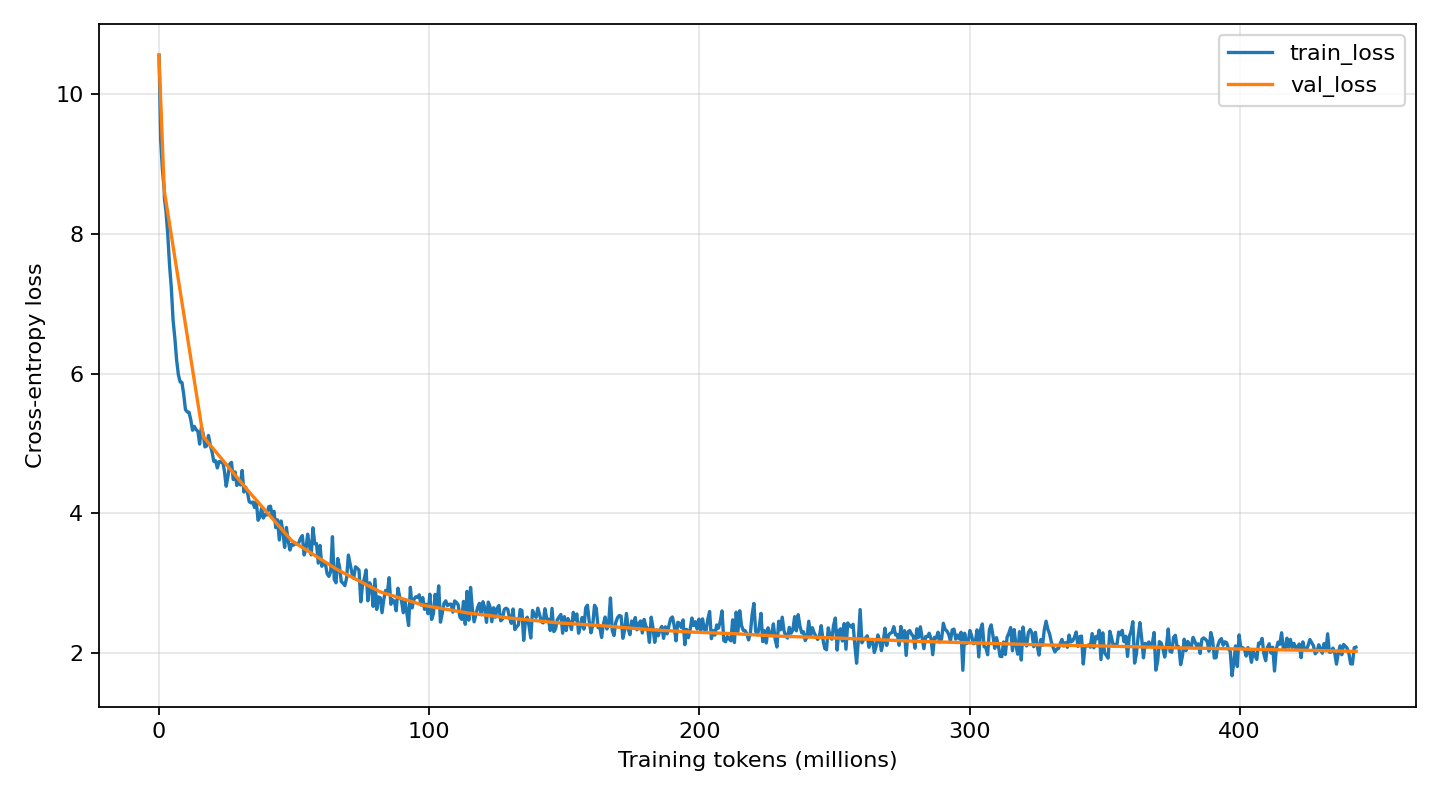

In [ ]:
if RESUME_FROM is not None:
    previous = Path(RESUME_FROM)
    for filename in ("latest.pt", "best.pt"):
        if not (previous / filename).is_file():
            raise FileNotFoundError(previous / filename)
    if previous.resolve() != RUN_DIR.resolve():
        if RUN_DIR.exists() and any(RUN_DIR.iterdir()):
            raise RuntimeError("Use the existing run directly or restore into an empty directory")
        shutil.copytree(previous, RUN_DIR, dirs_exist_ok=True)

train_decoder(CONFIG, DATA_DIR, RUN_DIR, max_steps=MAX_TRAIN_STEPS)
print(read_config(RUN_DIR / "progress.json"))
display(Image(filename=str(RUN_DIR / "training_validation_loss.png")))

## 5. Generate and evaluate

Run this section after training. To use an existing checkpoint, run Sections 1–3 and then this section, and set `GENERATION_RUN` to the attached run folder.

In [ ]:
GENERATION_RUN = RUN_DIR
DEV_OUT = Path("/kaggle/working/dev_500m_temp1")
TEST_OUT = Path("/kaggle/working/test_500m_temp1")
TEMPERATURE = 0.1
TOP_P = 0.95
MAX_NEW_TOKENS = 4096
TEST_PROMPTS = Path(LOCAL_TEST_PROMPTS) if LOCAL_TEST_PROMPTS is not None else None

In [ ]:
def unique_pairs(pairs):
    out = {}
    for key, value in pairs:
        if key in out:
            raise ValueError(f'Duplicate JSON ID: {key}')
        out[key] = value
    return out


In [ ]:
def load_prompts(path):
    with open(path, encoding='utf-8') as f:
        prompts = json.load(f, object_pairs_hook=unique_pairs)
    if not isinstance(prompts, dict) or not prompts:
        raise ValueError('Prompts must be a nonempty object mapping IDs to text records')
    for key, value in prompts.items():
        if not isinstance(value, dict) or not isinstance(value.get('text'), str) or (not value['text'].strip()):
            raise ValueError(f'Invalid prompt: {key}')
    return prompts


In [ ]:
def official_test(repo):
    from huggingface_hub import list_repo_files, hf_hub_download
    candidates = [p for p in list_repo_files(repo, repo_type='dataset') if p.startswith('Phase_1_Pretraining/Test/') and p.endswith('.json')]
    if len(candidates) != 1:
        raise ValueError(f'Expected one Phase 1 test JSON, found {candidates}. Download the correct file and pass --prompts explicitly.')
    return hf_hub_download(repo, candidates[0], repo_type='dataset')


In [ ]:
@torch.inference_mode()
def continuation(model, tok, prompt, device, max_new=2048, temperature=0.0, top_p=0.95):
    ids = tok.encode(prompt).ids
    context = model.config['context']
    if not ids or len(ids) >= context:
        raise ValueError(f'Prompt has {len(ids)} tokens; context is {context}. Refusing to silently truncate it.')
    history = list(ids)
    new = []
    past = None
    x = torch.tensor([ids], device=device)
    for _ in range(max_new):
        with torch.autocast(device_type=device.type, dtype=torch.float16, enabled=device.type == 'cuda'):
            logits, past = model(x, past=past, cache=True)
        logits = logits[0].float()
        logits[[PAD, UNK, BOS, EOS]] = -float('inf')
        if not torch.isfinite(logits[4:]).all():
            raise RuntimeError('Non-finite generation logits')
        if temperature <= 0:
            nxt = int(logits.argmax())
        else:
            probs = torch.softmax(logits / temperature, dim=-1)
            sorted_probs, indices = probs.sort(descending=True)
            remove = sorted_probs.cumsum(0) - sorted_probs > top_p
            sorted_probs[remove] = 0
            nxt = int(indices[torch.multinomial(sorted_probs, 1)])
        history.append(nxt)
        new.append(nxt)
        text = tok.decode(new, skip_special_tokens=True)
        words = text.split()
        if len(words) >= 129:
            return ' '.join(words[:128])
        if past[0][0].shape[2] >= context:
            past = None
            x = torch.tensor([history[-context:]], device=device)
        else:
            x = torch.tensor([[nxt]], device=device)
    raise RuntimeError(f'Generation did not produce 128 complete words in {max_new} tokens; increase --max-new. No padded/fabricated output was saved.')


In [ ]:
def validate_predictions(predictions, prompts):
    if set(predictions) != set(prompts):
        raise ValueError('Prediction IDs differ from prompt IDs')
    for key, value in predictions.items():
        if not isinstance(value, dict) or not isinstance(value.get('text'), str) or len(value['text'].split()) != 128:
            raise ValueError(f'Prediction {key} must contain exactly 128 words')


In [ ]:
def generate_predictions(run_dir, output_dir, prompts_path=None, temperature=0.0, top_p=0.95, max_new=2048, cpu=False, decoder=None):
    if decoder is None:
        decoder = continuation
    if temperature < 0 or not 0 < top_p <= 1:
        raise ValueError('Invalid decoding settings')
    run, out = (Path(run_dir), Path(output_dir))
    out.mkdir(parents=True, exist_ok=True)
    cfg = read_config(run / 'run_config.json')
    prompt_path = prompts_path or official_test(cfg['repo'])
    prompts = load_prompts(prompt_path)
    signature = {'checkpoint': digest_file(run / 'best.pt'), 'prompts': digest_file(prompt_path), 'tokenizer': digest_file(run / 'tokenizer.json'), 'temperature': temperature, 'top_p': top_p, 'max_new': max_new, 'seed': cfg['seed'], 'code': IMPLEMENTATION_VERSION}
    if (out / 'generation.json').exists() and read_config(out / 'generation.json') != signature:
        raise ValueError('Different generation configuration; use a new output directory')
    if (out / 'prediction.json').exists() and (not (out / 'generation.json').exists()):
        raise ValueError('Existing predictions have no provenance; choose a new output directory')
    write_json(out / 'generation.json', signature)
    predictions = read_config(out / 'prediction.json') if (out / 'prediction.json').exists() else {}
    if not set(predictions) <= set(prompts):
        raise ValueError('Unknown saved prediction IDs')
    for key, value in predictions.items():
        validate_predictions({key: value}, {key: prompts[key]})
    device = torch.device('cpu' if cpu else 'cuda')
    state = torch.load(run / 'best.pt', map_location='cpu', weights_only=False)
    if state['tokenizer_sha256'] != signature['tokenizer']:
        raise ValueError('Checkpoint/tokenizer mismatch')
    model = DecoderLM(**state['model_config'])
    model.load_state_dict(state['model'])
    model.to(device).eval()
    del state
    tok = ScratchByteBPE.from_file(str(run / 'tokenizer.json'))
    for key, record in prompts.items():
        if key in predictions:
            continue
        seed = (cfg['seed'] + int(fingerprint(key)[:8], 16)) % 2 ** 32
        torch.manual_seed(seed)
        predictions[key] = {'text': decoder(model, tok, record['text'], device, max_new, temperature, top_p)}
        write_json(out / 'prediction.json', predictions)
        if len(predictions) % 100 == 0:
            print(f'Generated {len(predictions)}/{len(prompts)}', flush=True)
    validate_predictions(predictions, prompts)
    archive = out / 'submission.zip'
    with zipfile.ZipFile(archive, 'w', compression=zipfile.ZIP_DEFLATED) as z:
        z.write(out / 'prediction.json', arcname='prediction.json')
    with zipfile.ZipFile(archive) as z:
        assert z.namelist() == ['prediction.json']
        validate_predictions(json.loads(z.read('prediction.json'), object_pairs_hook=unique_pairs), prompts)
    print(f'Validated {len(predictions)} continuations, 128 words each: {archive}')
    del model
    gc.collect()
    if torch.cuda.is_available():
        torch.cuda.empty_cache()
    return archive

### Development predictions and metrics

In [ ]:
subprocess.run([sys.executable, "-m", "pip", "install", "-q",
                "bert-score==0.3.13", "transformers>=4.45,<5"], check=True)

In [ ]:
class DuplicateJSONKeyError(ValueError):
    pass


In [ ]:
def reject_constant(v):
    raise ValueError(f"Non-standard JSON numeric value '{v}' is not allowed.")


In [ ]:
def pairs_no_duplicates(pairs):
    out = {}
    dup = []
    for k, v in pairs:
        if k in out:
            dup.append(k)
        out[k] = v
    if dup:
        raise DuplicateJSONKeyError(f'Duplicate JSON object keys detected: {list(dict.fromkeys(dup))[:10]}.')
    return out


In [ ]:
def load_json(path):
    try:
        with open(path, encoding='utf-8') as f:
            return json.load(f, object_pairs_hook=pairs_no_duplicates, parse_constant=reject_constant)
    except json.JSONDecodeError as e:
        raise ValueError(f'Invalid JSON in {path} at line {e.lineno}, column {e.colno}: {e.msg}') from e


In [ ]:
def lcs_length(a, b):
    if not a or not b:
        return 0
    if len(a) < len(b):
        a, b = (b, a)
    masks = {}
    for j, t in enumerate(a):
        masks[t] = masks.get(t, 0) | 1 << j
    state = 0
    for t in b:
        m = masks.get(t, 0)
        x = m | state
        y = state << 1 | 1
        state = x & ~(x - y)
    return state.bit_count() if hasattr(int, 'bit_count') else bin(state).count('1')


In [ ]:
def rouge_l_f1(p, r):
    pt = p.split()
    rt = r.split()
    if not pt or not rt:
        return 0.0
    l = lcs_length(pt, rt)
    if not l:
        return 0.0
    pp = l / len(pt)
    rr = l / len(rt)
    return 0.0 if pp + rr == 0 else 2 * pp * rr / (pp + rr)


In [ ]:
def ngrams(t, n):
    return Counter((tuple(t[i:i + n]) for i in range(len(t) - n + 1))) if len(t) >= n else Counter()


In [ ]:
def bleu4(preds, refs):
    order = 4
    clipped = [0] * order
    totals = [0] * order
    pl = rl = 0
    for p, r in zip(preds, refs):
        pl += len(p)
        rl += len(r)
        for n in range(1, order + 1):
            pn = ngrams(p, n)
            rn = ngrams(r, n)
            totals[n - 1] += sum(pn.values())
            for g, c in pn.items():
                clipped[n - 1] += min(c, rn.get(g, 0))
    prec = [clipped[i] / totals[i] if totals[i] else 0.0 for i in range(order)]
    if any((x <= 0 for x in prec)) or pl == 0:
        return 0.0
    bp = 1.0 if pl > rl else math.exp(1.0 - rl / pl)
    return bp * math.exp(sum((math.log(x) for x in prec)) / order)


In [ ]:
def evaluate_predictions(truth_path, prediction_path):
    import bert_score
    truth = load_json(truth_path)
    predictions = load_json(prediction_path)
    validate_predictions(predictions, truth)
    reference_texts = [truth[key]["text"].strip() for key in truth]
    prediction_texts = [predictions[key]["text"].strip() for key in truth]
    device = "cuda" if torch.cuda.is_available() else "cpu"
    _, _, f1 = bert_score.score(prediction_texts, reference_texts, lang="en",
                               batch_size=8, verbose=False, device=device)
    result = {
        "examples": len(truth),
        "BERTScore F1": float(f1.mean().item()),
        "ROUGE-L F1": sum(rouge_l_f1(p, r) for p, r in zip(prediction_texts, reference_texts)) / len(truth),
        "BLEU-4": bleu4([p.split() for p in prediction_texts], [r.split() for r in reference_texts])
    }
    print(json.dumps(result, indent=2))
    return result


In [ ]:
generate_predictions(GENERATION_RUN, DEV_OUT, prompts_path=DATA_DIR / "dev_prompts.json",
                     temperature=TEMPERATURE, top_p=TOP_P, max_new=MAX_NEW_TOKENS)
dev_metrics = evaluate_predictions(DATA_DIR / "dev_truth.json", DEV_OUT / "prediction.json")
write_json(DEV_OUT / "official_dev_metrics.json", dev_metrics)
gc.collect()
if torch.cuda.is_available():
    torch.cuda.empty_cache()

Generated 10/212
Generated 20/212
Generated 30/212
Generated 40/212
Generated 50/212
Generated 60/212
Generated 70/212
Generated 80/212
Generated 90/212
Generated 100/212
Generated 110/212
Generated 120/212
Generated 130/212
Generated 140/212
Generated 150/212
Generated 160/212
Generated 170/212
Generated 180/212
Generated 190/212
Generated 200/212
Generated 210/212
Validated 212 continuations, 128 words each: /kaggle/working/dev_500m_temp1/submission.zip


tokenizer_config.json:   0%|          | 0.00/25.0 [00:00<?, ?B/s]

config.json:   0%|          | 0.00/482 [00:00<?, ?B/s]

vocab.json: 0.00B [00:00, ?B/s]

merges.txt: 0.00B [00:00, ?B/s]

tokenizer.json: 0.00B [00:00, ?B/s]

model.safetensors:   0%|          | 0.00/1.42G [00:00<?, ?B/s]

Some weights of RobertaModel were not initialized from the model checkpoint at roberta-large and are newly initialized: ['pooler.dense.bias', 'pooler.dense.weight']
You should probably TRAIN this model on a down-stream task to be able to use it for predictions and inference.


{
  "examples": 212,
  "BERTScore F1": 0.8337932229042053,
  "ROUGE-L F1": 0.27778596698113206,
  "BLEU-4": 0.17052587400011215
}


### Test submission

In [ ]:
submission_path = generate_predictions(
    GENERATION_RUN, TEST_OUT, prompts_path=TEST_PROMPTS,
    temperature=TEMPERATURE, top_p=TOP_P, max_new=MAX_NEW_TOKENS,
)
display(FileLink(str(submission_path)))

### Optional recovery for incomplete temperature-0.1 generation

Use `recover_test_predictions(GENERATION_RUN, TEST_OUT, TEST_PROMPTS)` if a temperature-0.1 run stopped after saving partial predictions. Recovery retains completed IDs and writes into a separate folder.

In [ ]:
@torch.inference_mode()
def recovery_continuation(
    model, tok, prompt, device,
    max_new=4096, temperature=0.1, top_p=0.95
):
    if abs(float(temperature) - 0.1) > 1e-9:
        raise ValueError("This recovery function expects temperature 0.1.")

    ids = tok.encode(prompt).ids
    context = model.config["context"]

    if not ids or len(ids) >= context:
        raise ValueError(
            f"Prompt has {len(ids)} tokens; context is {context}."
        )

    base_seed = torch.initial_seed()
    temperatures = [0.1, 0.3, 0.5]
    last_word_count = 0

    for attempt, current_temperature in enumerate(temperatures):
        torch.manual_seed((base_seed + attempt) % (2 ** 32))

        history = list(ids)
        generated = []
        followers = defaultdict(set)
        past = None
        x = torch.tensor([ids], device=device)

        for _ in range(max_new):
            with torch.autocast(
                device_type=device.type,
                dtype=torch.float16,
                enabled=device.type == "cuda",
            ):
                logits, past = model(x, past=past, cache=True)

            scores = logits[0].float().clone()

            if not torch.isfinite(scores[4:]).all():
                raise RuntimeError("Non-finite generation logits.")

            scores[[PAD, UNK, BOS, EOS]] = -float("inf")

            # Block tokens that would repeat a generated four-token sequence.
            if len(generated) >= 3:
                banned = followers.get(tuple(generated[-3:]), ())
                if banned:
                    scores[list(banned)] = -float("inf")

            if not torch.isfinite(scores).any():
                break

            probabilities = torch.softmax(
                scores / current_temperature, dim=-1
            )
            sorted_probs, indices = probabilities.sort(descending=True)
            remove = sorted_probs.cumsum(0) - sorted_probs > top_p
            sorted_probs[remove] = 0

            nxt = int(indices[torch.multinomial(sorted_probs, 1)])
            generated.append(nxt)
            history.append(nxt)

            if len(generated) >= 4:
                followers[tuple(generated[-4:-1])].add(generated[-1])

            text = tok.decode(generated, skip_special_tokens=True)
            words = text.split()
            last_word_count = len(words)

            # Seeing word 129 confirms that word 128 is complete.
            if len(words) >= 129:
                if attempt:
                    print(
                        f"Recovered using temperature {current_temperature}.",
                        flush=True,
                    )
                return " ".join(words[:128])

            if past[0][0].shape[2] >= context:
                past = None
                x = torch.tensor([history[-context:]], device=device)
            else:
                x = torch.tensor([[nxt]], device=device)

        print(
            f"Attempt {attempt + 1}/3 at temperature "
            f"{current_temperature}: {last_word_count} words.",
            flush=True,
        )
        del past, x

    raise RuntimeError(
        "This prompt failed all three attempts. "
        "Completed predictions remain saved. "
        f"Last attempt produced {last_word_count} words."
    )

In [ ]:
def recover_test_predictions(run_dir, test_output, prompts_path=None):
    current_out = Path(test_output)

    # Allow this cell to be rerun after an interrupted recovery.
    if (current_out / "recovery_policy.json").exists():
        saved_policy = read_config(current_out / "recovery_policy.json")
        source_out = Path(saved_policy["inherited_predictions"])
        recovery_out = current_out
    else:
        source_out = current_out
        recovery_out = source_out.with_name(source_out.name + "_recovered")

    settings = read_config(source_out / "generation.json")

    if abs(float(settings["temperature"]) - 0.1) > 1e-9:
        raise ValueError(
            f"{source_out} was generated at temperature "
            f"{settings['temperature']}, not 0.1. "
            "Set TEST_OUT to your original 0.1 output folder."
        )

    TEMPERATURE = 0.1
    TOP_P = settings["top_p"]
    MAX_NEW_TOKENS = settings["max_new"]

    policy = {
        "version": "token-ngram-recovery-temp01-v1",
        "inherited_predictions": str(source_out),
        "attempt_temperatures": [0.1, 0.3, 0.5],
        "blocked_generated_ngram_size": 4,
        "top_p": TOP_P,
        "max_new_tokens_per_attempt": MAX_NEW_TOKENS,
    }

    # Reuse a matching recovery folder.
    # If its settings differ, create a fresh folder without changing old files.

    policy_path = recovery_out / "recovery_policy.json"

    if recovery_out.exists():
        matches = (
            policy_path.is_file()
            and read_config(policy_path) == policy
        )

        if not matches:
            recovery_out = source_out.with_name(
                source_out.name + f"_recovered_{time.time_ns()}"
            )

    recovery_out.mkdir(parents=True, exist_ok=True)
    policy_path = recovery_out / "recovery_policy.json"

    if not policy_path.exists():
        write_json(policy_path, policy)

    print("Using recovery folder:", recovery_out)

    for filename in ("generation.json", "prediction.json"):
        destination = recovery_out / filename
        if not destination.exists():
            shutil.copy2(source_out / filename, destination)
    return generate_predictions(
        run_dir, recovery_out, prompts_path=prompts_path, temperature=TEMPERATURE,
        top_p=TOP_P, max_new=MAX_NEW_TOKENS, decoder=recovery_continuation,
    )

In [70]:
if (TEST_OUT / "prediction.json").is_file() and not (TEST_OUT / "submission.zip").is_file():
    import base64
    from IPython.display import HTML

    submission_path = Path(recover_test_predictions(GENERATION_RUN, TEST_OUT, TEST_PROMPTS))
    encoded = base64.b64encode(submission_path.read_bytes()).decode("ascii")
    print("Completed submission:", submission_path)
    display(HTML(
        '<a download="submission_500m_temp01_recovered.zip" '
        f'href="data:application/zip;base64,{encoded}">'
        'Download completed submission ZIP</a>'
    ))

Using recovery folder: /kaggle/working/test_500m_temp1_recovered_1790850618844002674
Resuming into: /kaggle/working/test_500m_temp1_recovered_1790850618844002674
Already completed: 733
Token limit per attempt: 4096
Generated 740/1000
Generated 750/1000
Generated 760/1000
Generated 770/1000
Generated 780/1000
Generated 790/1000
Generated 800/1000
Generated 810/1000
Generated 820/1000
Generated 830/1000
Generated 840/1000
Generated 850/1000
Generated 860/1000
Generated 870/1000
Generated 880/1000
Generated 890/1000
Generated 900/1000
Generated 910/1000
Generated 920/1000
Generated 930/1000
Generated 940/1000
Generated 950/1000
Generated 960/1000
Generated 970/1000
Generated 980/1000
Generated 990/1000
Generated 1000/1000
Validated 1000 continuations, 128 words each: /kaggle/working/test_500m_temp1_recovered_1790850618844002674/submission.zip
Completed submission: /kaggle/working/test_500m_temp1_recovered_1790850618844002674/submission.zip
